# HyperSHAP Hands-On Tutorial

**Explaining Hyperparameter Optimization with Shapley Values and Interactions**

This notebook is the hands-on companion to the guest lecture on **HyperSHAP** — a
game-theoretic Python library for explaining Hyperparameter Optimization (HPO). It uses
Shapley values and interaction indices to answer questions like:

- *Which hyperparameters actually mattered for this run?* → **Ablation**
- *How much is there still to gain from tuning (subsets of) hyperparameters?* → **Tunability**
- *How sensitive is performance to varying (subsets of) hyperparameters?* → **Sensitivity**
- *Is my optimizer systematically biased towards/against certain hyperparameters?* → **Optimizer Bias**

## Agenda

1. [Setup: a toy HPO scenario](#1.-Setup:-a-toy-HPO-scenario)
2. [Wrapping it as an `ExplanationTask`](#2.-Wrapping-it-as-an-ExplanationTask)
3. [Ablation](#3.-Ablation:-why-did-this-configuration-perform-the-way-it-did?)
4. [Tunability](#4.-Tunability:-what's-still-worth-tuning?)
5. [Sensitivity](#5.-Sensitivity:-how-sensitive-is-performance-to-each-hyperparameter?)
6. [Optimizer Bias](#6.-Optimizer-Bias:-is-my-optimizer-playing-favorites?)
7. [Wrap-up & exercises](#7.-Wrap-up-&-exercises)

> Each section is short: a bit of theory, one or two code cells, a plot, and a **🧑‍💻 Try it
> yourself** exercise. Feel free to pause and experiment — all cells only take a few seconds
> to run.

Useful links: [GitHub](https://github.com/automl/HyperSHAP) ·
[Documentation](https://automl.github.io/HyperSHAP/) ·
[Paper](https://arxiv.org/abs/2502.01276)

## 1. Setup: a toy HPO scenario

To keep things reproducible and fast (no real training runs needed), we use a small
synthetic black-box function that *stands in* for the validation performance of an ML
pipeline with three hyperparameters:

| Hyperparameter | Type        | Range           | Role in the story                                   |
|-----------------|-------------|-----------------|------------------------------------------------------|
| `learning_rate` | float       | `[0.1, 1.5]`    | continuous hyperparameter                             |
| `depth`         | integer     | `[2, 10]`       | continuous(-ish) hyperparameter                       |
| `solver`        | categorical | `{adam, sgd}`   | switches which of the two other HPs actually matters  |

The function is intentionally simple so that we, as humans, can sanity-check whatever
HyperSHAP tells us:

- if `solver == adam`, performance is driven mostly by `depth` (plus a small `learning_rate`
  effect),
- if `solver == sgd`, performance is driven by an **interaction** between `learning_rate` and
  `depth`.

In your own work you would replace `eval_fun` with an actual training + validation run (or,
even simpler, with data you already collected from an HPO run — see Section 2).

In [1]:
import math

from ConfigSpace import Configuration, ConfigurationSpace

cs = ConfigurationSpace(
    name="toy_pipeline",
    space={
        "learning_rate": (0.1, 1.5),  # UniformFloat
        "depth": (2, 10),  # UniformInt
        "solver": ["adam", "sgd"],  # Categorical
    },
)


def eval_fun(config: Configuration) -> float:
    """Stand-in for 'train pipeline with `config`, return validation score'."""
    if config["solver"] == "adam":
        return math.sin(config["learning_rate"]) + config["depth"]
    return math.cos(config["learning_rate"] * config["depth"]) + 1.5


cs.seed(42)  # reproducibility


def random_search(config_space: ConfigurationSpace, fun, n: int) -> Configuration:
    """Tiny random-search helper: sample n configs, return the best one."""
    best_config, best_val = None, None
    for config in config_space.sample_configuration(n):
        val = fun(config)
        if best_config is None or val > best_val:
            best_config, best_val = config, val
    return best_config


# A configuration nobody tuned (our "default"/baseline) ...
baseline_config = cs.get_default_configuration()
# ... and a configuration found by a (small) HPO run.
config_of_interest = random_search(cs, eval_fun, 1_000)

print("Baseline        :", baseline_config, "-> value =", round(eval_fun(baseline_config), 3))
print("Config of interest:", config_of_interest, "-> value =", round(eval_fun(config_of_interest), 3))

Baseline        : Configuration(values={
  'depth': 6,
  'learning_rate': 0.8,
  'solver': 'adam',
}) -> value = 6.717
Config of interest: Configuration(values={
  'depth': 10,
  'learning_rate': 1.4643661712784,
  'solver': np.str_('adam'),
}) -> value = 10.994


## 2. Wrapping it as an `ExplanationTask`

HyperSHAP treats hyperparameters as *players* in a cooperative game and the model's
performance as the *value* a coalition of players can achieve. To play this game it needs a
**surrogate model** that can predict performance for *any* configuration (including ones that
were never actually evaluated) — this is what makes Shapley-value computation tractable.

`ExplanationTask` hides this behind three convenience constructors:

- `ExplanationTask.from_function(config_space, function, n_samples=..., base_model=...)` — samples
  `n_samples` random configurations, evaluates them with your black-box function, and fits a
  surrogate (`RandomForestRegressor` by default). **This is what we use below.**
- `ExplanationTask.from_data(config_space, data, base_model=...)` — same, but you already have a
  list of `(Configuration, performance)` pairs (e.g. from a previous HPO run, or an Optuna study
  via `hypershap.optuna_task`).
- `ExplanationTask.from_base_model(config_space, base_model)` — you already trained a surrogate
  yourself.

We then hand the `ExplanationTask` to `HyperSHAP`, which is the object we call `.ablation()`,
`.tunability()`, `.sensitivity()`, `.optimizer_bias()`, and the various `.plot_*()` methods on.

In [2]:
from sklearn.ensemble import RandomForestRegressor

from hypershap.hypershap import HyperSHAP
from hypershap.task import ExplanationTask

explanation_task = ExplanationTask.from_function(
    config_space=cs,
    function=eval_fun,
    n_samples=2_000,
    base_model=RandomForestRegressor(random_state=0),
)

hypershap = HyperSHAP(explanation_task=explanation_task)
print("Hyperparameters:", explanation_task.get_hyperparameter_names())

Hyperparameters: ['depth', 'learning_rate', 'solver']


## 3. Ablation: why did this configuration perform the way it did?

**Question:** starting from `baseline_config`, we changed some hyperparameter values and ended
up at `config_of_interest`. Which of those *changes* (and which combinations of changes) are
responsible for the performance difference?

Ablation is a **local, contrastive** explanation: it always compares two specific
configurations, similar to how classic SHAP explains one prediction relative to a reference
point.

In [17]:
iv_ablation = hypershap.ablation(
    config_of_interest=config_of_interest,
    baseline_config=baseline_config,
)
hypershap.get_interaction_values_with_names()

{(): 0.0,
 ('depth',): 3.9968644007525236,
 ('learning_rate',): 0.2770060196440063,
 ('solver',): 2.8133115553379616e-12,
 ('depth', 'learning_rate'): 0.003371213846035763,
 ('depth', 'solver'): 8.43323589997481e-12,
 ('learning_rate', 'solver'): -8.433716379340418e-12}

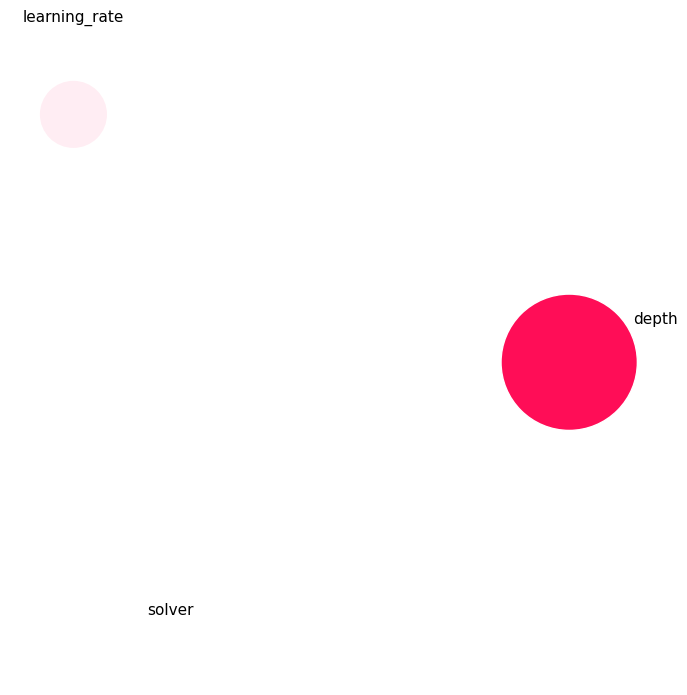

In [18]:
hypershap.plot_si_graph()

The **SI-graph** above shows each hyperparameter as a node and each pairwise interaction
as an edge; node/edge size and color encode the (signed) contribution to the performance gain
between baseline and configuration of interest. Two more views of the *same* interaction
values, useful for different audiences:

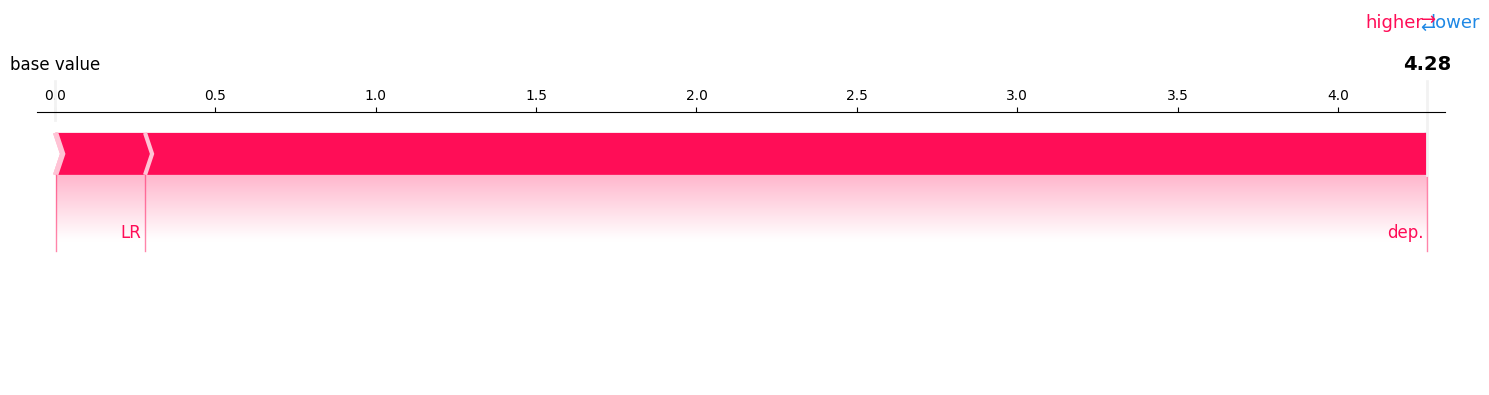

In [9]:
hypershap.plot_force()  # SHAP-style force plot: additive push from baseline to prediction

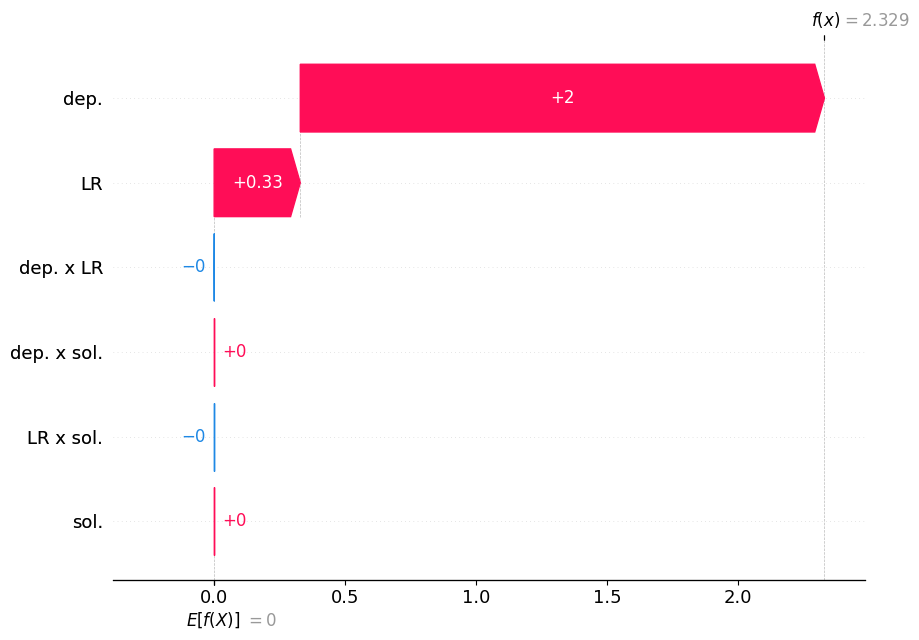

In [6]:
hypershap.plot_waterfall()  # ordered, additive breakdown of the performance gap

**🧑‍💻 Try it yourself**

1. Construct your own `my_config` (e.g. `Configuration(cs, values={"learning_rate": 1.4, "depth": 9, "solver": "sgd"})`)
   and re-run the ablation between `baseline_config` and `my_config`. Does the picture match
   your intuition about the function?
2. Swap `baseline_config` and `config_of_interest` — how do the interaction values change?
   (Hint: think about what "baseline" means for the sign of the contributions.)

In [7]:
# Your code here



## 4. Tunability: what's still worth tuning?

**Question:** starting from a single `baseline_config`, how much performance could we *gain* by
tuning a given subset of hyperparameters (while leaving the rest at their baseline value)?

Unlike ablation, tunability does not need a second, already-known "good" configuration — for
every subset (coalition) of hyperparameters it internally runs a small random search over just
that subset and asks: *what's the best value this coalition can achieve?* This makes tunability
a **global, baseline-relative** explanation: it tells you where the *remaining potential*
sits, before you've done any real tuning.

We use the config space's default configuration as baseline — i.e. "the pipeline before
anyone touched the hyperparameters".

In [8]:
default_config = cs.get_default_configuration()
print("Default (baseline) config:", default_config)

iv_tunability = hypershap.tunability(baseline_config=default_config, n_samples=5_000)
print(iv_tunability)

Default (baseline) config: Configuration(values={
  'depth': 6,
  'learning_rate': 0.8,
  'solver': 'adam',
})


InteractionValues(
    index=FSII, max_order=2, min_order=0, estimated=False, estimation_budget=None,
    n_players=3, baseline_value=0.0,
    Top 10 interactions:
        (0,): 3.996864400751224
        (1,): 0.2787380605083938
        (0, 1): 0.0037693871423860304
        (0, 2): 9.213044638212264e-12
        (2,): 3.073557217198387e-12
        (): 0.0
        (1, 2): -9.213548946096384e-12
)


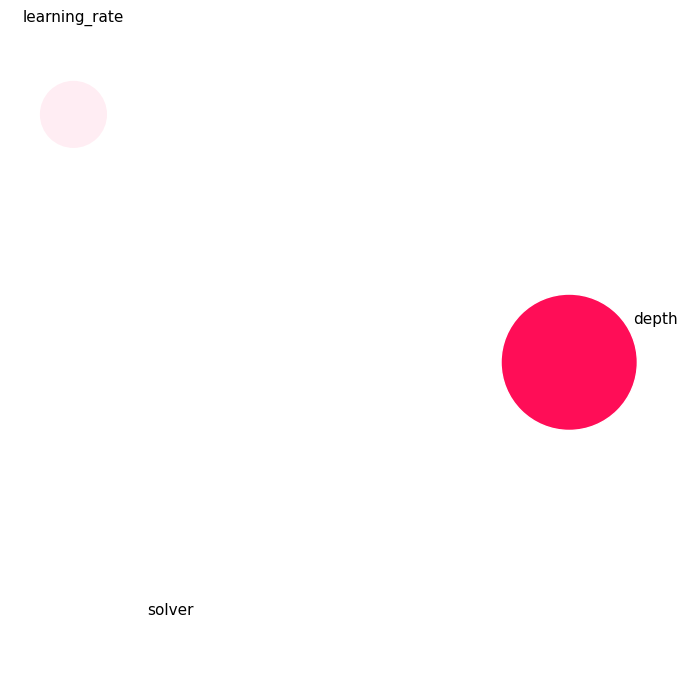

In [9]:
hypershap.plot_si_graph()

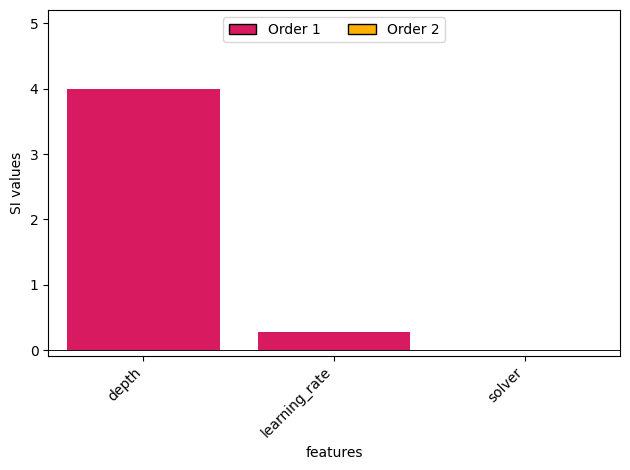

In [10]:
hypershap.plot_stacked_bar()  # contribution per interaction order (main effects vs. pairwise)

The default configuration happens to have `solver = adam`, and under that branch
`eval_fun` is simply `sin(learning_rate) + depth` — additive, no interaction. That is exactly
what tunability picks up: almost the entire achievable gain is attributed to tuning `depth`
alone (its range contributes up to +8), a smaller amount to `learning_rate`, and (close to)
**nothing** to `solver` or to any interaction. Switching to `sgd` *would* introduce an
interaction — but its `cos(...)  + 1.5` branch is bounded to a much smaller range, so relative
to what `depth` alone can already achieve, touching `solver` is not worth much *in terms of the
best value you can reach*. Keep this in mind for the next section — "not worth tuning" and
"has no effect" are not the same thing.

**🧑‍💻 Try it yourself**

1. Re-run `hypershap.tunability(...)` with `baseline_config` from Section 1 (the randomly
   sampled one, which may have `solver = sgd`) instead of `default_config` — does the ranking
   of hyperparameters change?
2. `hypershap.mistunability(baseline_config=...)` answers a related but different question:
   *how much could performance be **lost** by mistuning a subset?* Try it and compare.

In [11]:
# Your code here



## 5. Sensitivity: how sensitive is performance to each hyperparameter?

**Question:** if we let a subset of hyperparameters vary randomly (while keeping the rest at
their baseline value), how much does performance *fluctuate* as a result?

Sensitivity looks superficially similar to tunability — both use random sampling over
coalitions of hyperparameters — but they aggregate very differently:

| | aggregates via | answers |
|---|---|---|
| **Tunability** | **max** performance over samples | "how much could I *gain* by tuning this subset?" |
| **Sensitivity** | **variance** of performance over samples | "how much does this subset *move the needle*, for better or worse?" |

A hyperparameter can be highly *sensitive* (performance swings wildly as you change it) without
being very *tunable* (there may be no reliable direction to move it in), and vice versa — which
is exactly the kind of nuance a single "feature importance" number cannot capture.

In [12]:
iv_sensitivity = hypershap.sensitivity(baseline_config=default_config, n_samples=5_000)
print(iv_sensitivity)

InteractionValues(
    index=FSII, max_order=2, min_order=0, estimated=False, estimation_budget=None,
    n_players=3, baseline_value=0.0,
    Top 10 interactions:
        (2,): 6.686276770703892
        (0,): 6.645406140627757
        (1, 2): 0.11859461967358643
        (1,): 0.11649591854471406
        (): 0.0
        (0, 1): -0.10479599225537238
        (0, 2): -3.085998464371106
)


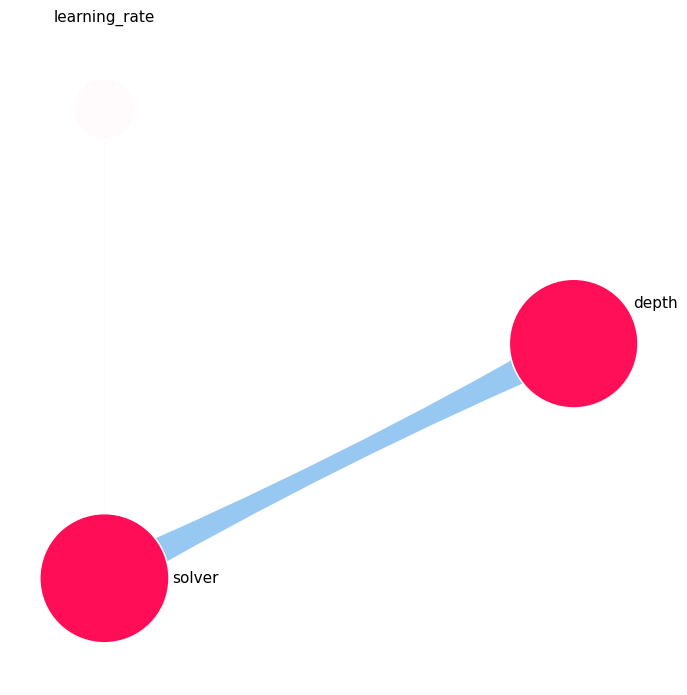

In [13]:
hypershap.plot_si_graph()

Notice how differently `solver` scores here compared to tunability: tunability found it
almost irrelevant (≈0), but sensitivity ranks it among the *most* impactful hyperparameters,
alongside a strong negative `depth`–`solver` interaction. That is because randomly flipping
`solver` (while `depth`/`learning_rate` stay at baseline) frequently jumps performance between
the large `adam` branch and the small, bounded `sgd` branch — a big swing, even though *tuning
towards* `sgd` never actually pays off. This is precisely the nuance a single "how important is
this hyperparameter" score cannot express: `solver` is highly **sensitive** but has low
**tunability** — variance without upside.

**🧑‍💻 Try it yourself**

1. Print `hypershap.get_interaction_values_with_names(iv_tunability)` next to
   `hypershap.get_interaction_values_with_names(iv_sensitivity)` side by side. Do the two
   methods agree on which hyperparameter matters most?
2. What would you expect for a hyperparameter that has *no* effect at all on `eval_fun`? Add a
   dummy hyperparameter to `cs` that `eval_fun` ignores, rebuild the `ExplanationTask`, and
   check that both tunability and sensitivity correctly attribute (close to) zero importance to
   it.

In [14]:
# Your code here
print("Tunability :", hypershap.get_interaction_values_with_names(iv_tunability))
print("Sensitivity:", hypershap.get_interaction_values_with_names(iv_sensitivity))

Tunability : {(): 0.0, ('depth',): 3.996864400751224, ('learning_rate',): 0.2787380605083938, ('solver',): 3.073557217198387e-12, ('depth', 'learning_rate'): 0.0037693871423860304, ('depth', 'solver'): 9.213044638212264e-12, ('learning_rate', 'solver'): -9.213548946096384e-12}
Sensitivity: {(): 0.0, ('depth',): 6.645406140627757, ('learning_rate',): 0.11649591854471406, ('solver',): 6.686276770703892, ('depth', 'learning_rate'): -0.10479599225537238, ('depth', 'solver'): -3.085998464371106, ('learning_rate', 'solver'): 0.11859461967358643}


## 6. Optimizer Bias: is my optimizer playing favorites?

**Question:** does a given HPO *optimizer* systematically explore some hyperparameters more
effectively than others, compared to a reference ensemble of optimizers (e.g. plain random
search)?

This is a different kind of game: instead of comparing configurations, we compare
**optimizers**. For each coalition of hyperparameters, we let the *optimizer of interest* search
only within that coalition (freezing the rest at baseline) and compare the best value it finds
against what an *ensemble* of reference optimizers finds for the same coalition. Large negative
interaction values point to hyperparameters (or hyperparameter groups) that the optimizer of
interest under-explores relative to the reference.

To make the bias clearly visible, we switch to a scenario with **three purely continuous,
interacting** hyperparameters, and deliberately build a "flawed" optimizer that only ever tunes
one of them.

In [15]:
import numpy as np

bias_cs = ConfigurationSpace(
    name="optimizer_bias_space",
    space={
        "a": (0.1, 1.5),
        "b": (0.1, 1.5),
        "c": (0.1, 1.5),
    },
)


def bias_eval_fun(config: Configuration) -> float:
    # 'a' and 'b' interact (a/b term); 'c' only contributes additively.
    return config["a"] + config["b"] + config["c"] + (config["a"] / config["b"])


bias_cs.seed(42)
bias_baseline_config = bias_cs.sample_configuration()

bias_explanation_task = ExplanationTask.from_function(
    config_space=bias_cs,
    function=bias_eval_fun,
    n_samples=50_000,
    base_model=RandomForestRegressor(random_state=0),
)
hypershap_bias = HyperSHAP(explanation_task=bias_explanation_task)

# For reference: tunability tells us 'a' and 'b' (and their interaction) matter most.
iv_bias_tunability = hypershap_bias.tunability(baseline_config=bias_baseline_config, n_samples=50_000)
print(iv_bias_tunability)

InteractionValues(
    index=FSII, max_order=2, min_order=0, estimated=False, estimation_budget=None,
    n_players=3, baseline_value=0.0,
    Top 10 interactions:
        (0, 1): 5.743225224341246
        (1,): 4.010385386123778
        (0,): 3.6827597434638406
        (2,): 1.3802539304505075
        (): 0.0
        (0, 2): -0.3576498691371494
        (1, 2): -0.5990532227346029
)


In [16]:
from hypershap.task import BaselineExplanationTask
from hypershap.utils import RandomConfigSpaceSearcher


class SubConfigSpaceSearcher(RandomConfigSpaceSearcher):
    """A 'flawed' optimizer that only ever tunes hyperparameters flagged in `parameter_activation`;
    every other hyperparameter is frozen at its baseline value, no matter which coalition is asked about.
    """

    def __init__(
        self,
        explanation_task: BaselineExplanationTask,
        parameter_activation: list[bool],
        n_samples: int = 10_000,
    ) -> None:
        super().__init__(explanation_task, n_samples=n_samples)
        self.parameter_activation = np.array(parameter_activation)

    def search(self, coalition: np.ndarray) -> float:
        temp_random_sample = self.random_sample.copy()
        activation_map = np.logical_and(self.parameter_activation, coalition)
        blind_coalition = ~activation_map
        column_index = np.where(blind_coalition)
        temp_random_sample[:, column_index] = self.explanation_task.baseline_config.get_array()[column_index]
        vals = np.array(self.explanation_task.surrogate_model.evaluate(temp_random_sample))
        return vals.max()


baseline_task = BaselineExplanationTask(
    config_space=bias_cs,
    surrogate_model=bias_explanation_task.surrogate_model,
    baseline_config=bias_baseline_config,
)

# The optimizer of interest only ever tunes hyperparameter 'b' ...
flawed_optimizer = SubConfigSpaceSearcher(
    explanation_task=baseline_task,
    parameter_activation=[False, True, False],
    n_samples=10_000,
)
# ... compared against an ensemble containing a proper random search over all hyperparameters.
reference_ensemble = [RandomConfigSpaceSearcher(explanation_task=baseline_task, n_samples=50_000)]

iv_optimizer_bias = hypershap_bias.optimizer_bias(
    optimizer_of_interest=flawed_optimizer,
    optimizer_ensemble=reference_ensemble,
)
print(iv_optimizer_bias)

InteractionValues(
    index=FSII, max_order=2, min_order=0, estimated=False, estimation_budget=None,
    n_players=3, baseline_value=0.0,
    Top 10 interactions:
        (1, 2): 0.5990532227345929
        (0, 2): 0.3576498691371589
        (): 0.0
        (1,): -0.0774837815636936
        (2,): -1.3802539304505035
        (0,): -3.682759743463859
        (0, 1): -5.743225224341235
)


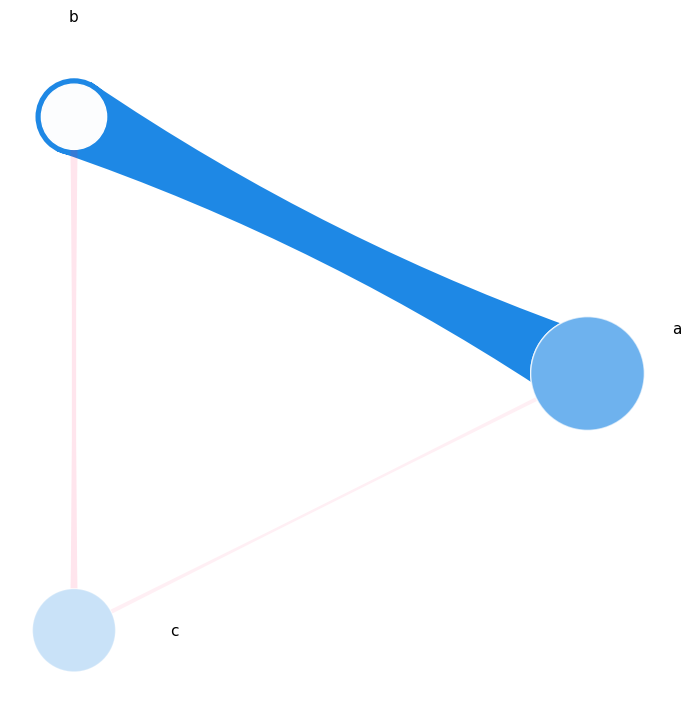

In [17]:
hypershap_bias.plot_si_graph()

Since the flawed optimizer never touches `a` and `c`, and `a` only pays off *together
with* `b` (through the `a / b` term), we expect the largest negative contributions on `a` alone
and on the `(a, b)` interaction — exactly what shows up above.

**🧑‍💻 Try it yourself**

1. Change `parameter_activation` to `[True, True, False]` (tune `a` and `b`, still ignore `c`).
   How does the bias picture change?
2. Add a second, *good* optimizer to `optimizer_ensemble` (e.g. another
   `RandomConfigSpaceSearcher` with a much larger `n_samples`) and see how sensitive the result
   is to what you consider "the reference".

In [18]:
# Your code here



## 7. Wrap-up & exercises

| Explanation task | Compares | Aggregation | Typical question |
|---|---|---|---|
| **Ablation** | two specific configurations | — (contrastive) | "Why did *this* config beat *that* one?" |
| **Tunability** | subset vs. baseline | `max` over samples | "What's still worth tuning?" |
| **Mistunability** | subset vs. baseline | `min` over samples | "How badly could I mess this subset up?" |
| **Sensitivity** | subset vs. baseline | `variance` over samples | "How much does this subset move the needle?" |
| **Optimizer Bias** | optimizer vs. ensemble | per-coalition best value | "Is my optimizer neglecting some hyperparameters?" |

All five return a shapiq `InteractionValues` object, so anything you know about
inspecting/plotting Shapley values from the `shapiq` ecosystem applies directly, and all of
`plot_si_graph`, `plot_upset`, `plot_force`, `plot_waterfall`, and `plot_stacked_bar` work for
any of them.

### Where to go next

- `examples/optuna-example.ipynb` — plug in a *real* [Optuna](https://optuna.org/) study via
  `from_optuna_study` instead of a synthetic `eval_fun`.
- `examples/carps-benchmark-example.ipynb` — apply HyperSHAP to a
  [CARP-S](https://github.com/automl/CARP-S) benchmark.
- `examples/explanation-task-example.ipynb` — all three ways of constructing an
  `ExplanationTask` (`from_function`, `from_data`, `from_base_model`) in one place.
- [Paper](https://arxiv.org/abs/2502.01276) — the game-theoretic formalization behind all of
  the above.

### 🧑‍💻 Open exercise

Pick a hyperparameter optimization problem you actually care about (or reuse the config space
from any earlier exercise you did in this course), and try to answer, using HyperSHAP:

1. Which single explanation task would you reach for first, and why?
2. Run it, plot it, and write one sentence summarizing what it told you that a plain "loop over
   hyperparameters and check correlation with performance" would have missed.